# LAB 06 — Attention Mechanism
**From Recurrent State to Context-Aware Representation** · Môn NLP & ứng dụng, HK I 2026

Notebook gồm: core NumPy (kiểm tra), Exp 1 (attention distribution), Exp 2 (query / scaling / temperature),
Exp 3 (self-attention visualization), Exp 4 (LSTM vs Attention trên IMDb), Exp 5 (chi phí O(T²)),
Application, dữ liệu cho error analysis.  
Các ô đánh dấu ✍️ là phần diễn giải **sinh viên tự viết**.

In [1]:
import time, warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

import attention_numpy as an
import attention_model as am
import preprocessing as pp

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_colwidth", 120)
print(f"PyTorch {torch.__version__} | device: {am.DEVICE}")

PyTorch 2.14.1+cu126 | device: cuda


## 1. Core: kiểm tra `attention_numpy.py` với các bài tính tay

In [2]:
# Bài 1
q = np.array([1, 2]); K = np.array([[1, 0], [0, 1], [1, 1]])
print("Bài 1 scores:", K @ q)
# Bài 2
a = an.softmax([1, 2, 3]); print("Bài 2 softmax:", a, "| sum =", a.sum())
# Bài 3
V3 = np.array([[1, 0], [0, 1], [2, 2]]); print("Bài 3 context:", np.array([.1, .2, .7]) @ V3)
# Bài 4 (dot-product thường, và scaled)
q4 = np.array([[1, 0]]); K4 = np.array([[1, 0], [0, 1], [1, 1]]); V4 = np.array([[1, 0], [0, 2], [2, 1]])
for scale in (False, True):
    s, w, c = an.scaled_dot_product_attention(q4, K4, V4, scale=scale)
    print(f"Bài 4 (scale={scale}): scores={s[0]} weights={w[0]} context={c[0]}")
# So khớp với PyTorch (chỉ để verify)
import torch.nn.functional as F
rng = np.random.default_rng(0); Q, Kk, Vv = (rng.normal(size=(6, 8)) for _ in range(3))
_, _, c = an.scaled_dot_product_attention(Q, Kk, Vv)
ref = F.scaled_dot_product_attention(*(torch.tensor(x) for x in (Q, Kk, Vv))).numpy()
print("max |NumPy - torch| =", np.abs(c - ref).max())

Bài 1 scores: [1 2 3]
Bài 2 softmax: [0.09   0.2447 0.6652] | sum = 0.9999999999999999
Bài 3 context: [1.5 1.6]
Bài 4 (scale=False): scores=[1. 0. 1.] weights=[0.4223 0.1554 0.4223] context=[1.267 0.733]
Bài 4 (scale=True): scores=[0.7071 0.     0.7071] weights=[0.4011 0.1978 0.4011] context=[1.2033 0.7967]
max |NumPy - torch| = 2.220446049250313e-16


### 1.1 Numerical stability

In [3]:
x = [1000, 1001, 1002]
with np.errstate(all="ignore"):
    print("naive :", an.naive_softmax(x))
print("stable:", an.softmax(x), "| softmax([0,1,2]) =", an.softmax([0, 1, 2]))

naive : [nan nan nan]
stable: [0.09   0.2447 0.6652] | softmax([0,1,2]) = [0.09   0.2447 0.6652]


**Tại sao trừ max(x) không đổi kết quả?**

Softmax chỉ phụ thuộc vào *hiệu* giữa các phần tử: `exp(xᵢ − m) / Σⱼ exp(xⱼ − m) = [exp(xᵢ)·exp(−m)] / [Σⱼ exp(xⱼ)·exp(−m)]`. Thừa số `exp(−m)` xuất hiện ở cả tử và mẫu nên triệt tiêu, kết quả không đổi (đúng như `softmax([1000,1001,1002]) = softmax([0,1,2])`). Nhưng sau khi trừ max thì mọi số mũ ≤ 0 nên `exp(·) ≤ 1`, không bị overflow; còn phần tử lớn nhất cho `exp(0) = 1` nên mẫu số ≥ 1, không bị chia cho 0. Bản naive tính `exp(1000) = inf` nên ra `nan`.

### 1.2 Scaling và temperature trên `QKᵀ = [4, 2, 0]`, d_k = 4

In [4]:
s = np.array([4., 2., 0.])
print("Không scale:", an.softmax(s), "| max =", an.softmax(s).max().round(4))
print("Scale /√4  :", an.softmax(s / 2), "| max =", an.softmax(s / 2).max().round(4))
rows = []
for T in (0.5, 1.0, 2.0):
    p = an.softmax(s, temperature=T)
    rows.append({"Temperature": T, "weights": np.round(p, 4), "Max weight": p.max().round(4), "Entropy (nats)": an.entropy(p).round(4)})
pd.DataFrame(rows)

Không scale: [0.8668 0.1173 0.0159] | max = 0.8668
Scale /√4  : [0.6652 0.2447 0.09  ] | max = 0.6652


,Temperature,weights,Max weight,Entropy (nats)
0,0.5,"[0.9817, 0.018, 0.0003]",0.9817,0.0930
1,1.0,"[0.8668, 0.1173, 0.0159]",0.8668,0.4411
2,2.0,"[0.6652, 0.2447, 0.09]",0.6652,0.8324


**Nhận xét scaling / temperature:**

- **Scaling:** chia `√d_k = 2` làm score từ `[4,2,0]` thành `[2,1,0]`; weight lớn nhất giảm từ 0.8668 xuống 0.6652, phân phối bớt nhọn. Bảng d_k ở mục 2.1 cho thấy lý do: score không scale có độ lệch chuẩn ≈ `√d_k`, nên khi d_k tăng thì softmax bão hòa (max weight 0.479 → 0.969 từ d_k=4 đến 1024), còn khi scale thì max weight ổn định ~0.30–0.32 (gần uniform 1/T = 0.1 không phụ thuộc d_k).
- **Temperature:** T nhỏ làm phân phối nhọn hơn (T=0.5: max 0.9817, entropy 0.0930, gần one-hot); T lớn làm phẳng hơn (T=2: max 0.6652, entropy 0.8324). Chia `√d_k` thực chất là dùng `T = √d_k` cố định để giữ độ nhọn của softmax ổn định.

## 2. Experiment 1 & 2 — attention distribution và đổi query

Embedding ở đây là **đặc trưng giả lập 3 chiều** `[sentiment, topic, intensity]` do mình gán tay cho từng token
(không phải embedding học được), để thấy rõ cơ chế score → softmax → weight. Query giả lập cũng là vector 3 chiều.

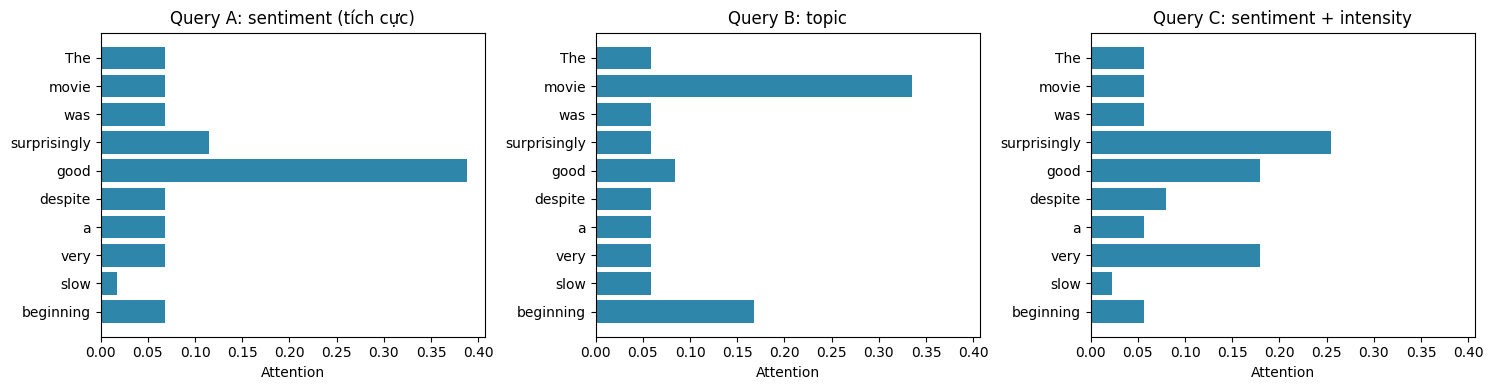

,Token,Score,Attention
0,The,0.000,0.0686
1,movie,0.000,0.0686
2,was,0.000,0.0686
3,surprisingly,0.520,0.1153
4,good,1.732,0.3876
5,despite,0.000,0.0686
6,a,0.000,0.0686
7,very,0.000,0.0686
8,slow,-1.386,0.0172
9,beginning,0.000,0.0686


,A: sentiment (tích cực),B: topic,C: sentiment + intensity
The,0.069,0.059,0.057
movie,0.069,0.335,0.057
was,0.069,0.059,0.057
surprisingly,0.115,0.059,0.254
good,0.388,0.084,0.180
despite,0.069,0.059,0.080
a,0.069,0.059,0.057
very,0.069,0.059,0.180
slow,0.017,0.059,0.023
beginning,0.069,0.167,0.057


In [5]:
tokens = "The movie was surprisingly good despite a very slow beginning".split()
feat = {  # [sentiment, topic, intensity]
    "The": [0, 0, 0], "movie": [0, 1, 0], "was": [0, 0, 0], "surprisingly": [.3, 0, 1], "good": [1, .2, 0],
    "despite": [0, 0, .3], "a": [0, 0, 0], "very": [0, 0, 1], "slow": [-.8, 0, 0], "beginning": [0, .6, 0]}
Kx = np.array([feat[t] for t in tokens], dtype=float)
queries = {"A: sentiment (tích cực)": [3, 0, 0], "B: topic": [0, 3, 0], "C: sentiment + intensity": [2, 0, 2]}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
tab = {}
for ax, (name, qv) in zip(axes, queries.items()):
    sc, w, ctx = an.scaled_dot_product_attention(np.array([qv], float), Kx, Kx)
    tab[name] = (sc[0], w[0])
    ax.barh(tokens[::-1], w[0][::-1], color="#2e86ab"); ax.set_title(f"Query {name}"); ax.set_xlabel("Attention")
plt.tight_layout(); plt.show()

sc, w = tab["A: sentiment (tích cực)"]
display(pd.DataFrame({"Token": tokens, "Score": sc.round(3), "Attention": w.round(4)}))
display(pd.DataFrame({n: v[1].round(3) for n, v in tab.items()}, index=tokens))

**Attention distribution có đổi khi đổi query không? Vì sao?**

Có. Weights `α = softmax(q·kᵢ)` phụ thuộc vào query nên đổi query là đổi phân phối, trong khi keys giữ nguyên. Với query A (sentiment tích cực) attention dồn vào "good" (0.388) và "surprisingly" (0.115), còn "slow" (sentiment âm) bị nén xuống 0.017. Với query B (topic), attention chuyển sang "movie" (0.335) và "beginning" (0.167), "good" chỉ còn 0.084. Với query C (sentiment + intensity), "surprisingly" (0.254), "good" và "very" (0.180) đều cao. Vậy query quyết định "đang tìm loại thông tin nào" và cùng một câu cho các context vector khác nhau. Lưu ý đặc trưng ở đây do gán tay nên chỉ minh họa cơ chế, không phải embedding học được.

### 2.1 Scaling theo `d_k` (vì sao phải chia √d_k)

,d_k,std(score) không scale,mean max-weight (không scale),mean max-weight (scale)
0,4,2.0,0.479,0.298
1,16,4.0,0.721,0.314
2,64,8.0,0.860,0.323
3,256,16.0,0.931,0.323
4,1024,32.0,0.969,0.319


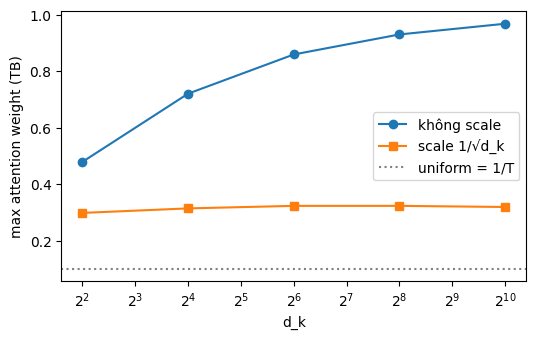

In [6]:
rng = np.random.default_rng(0)
dims = [4, 16, 64, 256, 1024]; T = 10; trials = 500
res = []
for d in dims:
    mx_u, mx_s = [], []
    for _ in range(trials):
        q = rng.normal(size=(1, d)); Kr = rng.normal(size=(T, d))
        mx_u.append(an.scaled_dot_product_attention(q, Kr, Kr, scale=False)[1].max())
        mx_s.append(an.scaled_dot_product_attention(q, Kr, Kr, scale=True)[1].max())
    res.append({"d_k": d, "std(score) không scale": (np.sqrt(d)).round(2), "mean max-weight (không scale)": np.mean(mx_u).round(3),
                "mean max-weight (scale)": np.mean(mx_s).round(3)})
res = pd.DataFrame(res); display(res)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(res["d_k"], res["mean max-weight (không scale)"], "o-", label="không scale")
ax.plot(res["d_k"], res["mean max-weight (scale)"], "s-", label="scale 1/√d_k")
ax.axhline(1 / T, ls=":", c="gray", label="uniform = 1/T"); ax.set_xscale("log", base=2)
ax.set_xlabel("d_k"); ax.set_ylabel("max attention weight (TB)"); ax.legend(); plt.show()

**Nhận xét:**

Khi d_k tăng, độ lệch chuẩn của score không scale tăng theo `√d_k` (2 → 32), nên max attention weight trung bình tăng từ 0.479 (d_k=4) lên 0.969 (d_k=1024): softmax gần như one-hot, gradient qua softmax rất nhỏ nên khó học. Khi scale `1/√d_k`, max weight ổn định quanh 0.30–0.32 với mọi d_k, cho thấy scaling chuẩn hóa phương sai của score về ~1 và giữ softmax ở vùng có gradient tốt. Đường "không scale" trên đồ thị tiến về 1, đường "scale" gần phẳng.

## 3. Self-attention bằng tay trên `[I, like, cats]` (ví dụ tự đặt)

Đề bảo W_Q, W_K, W_V 'được cung cấp' nhưng PDF không in ma trận cụ thể, nên dùng ma trận ví dụ dưới đây (có thể thay bằng ma trận của giảng viên).

In [7]:
X = np.array([[1., 0.], [0., 1.], [1., 1.]])        # I, like, cats
Wq = np.array([[1., 0.], [0., 1.]]); Wk = np.array([[1., 1.], [0., 1.]]); Wv = np.array([[1., 0.], [1., 1.]])
Qs, Ks, Vs, S, A, C = an.self_attention(X, Wq, Wk, Wv)
for n, m in [("Q", Qs), ("K", Ks), ("V", Vs), ("QKᵀ", Qs @ Ks.T), ("scores/√d_k", S), ("A", A), ("C = A V", C)]:
    print(n, "\n", m, "\n")

Q 
 [[1. 0.]
 [0. 1.]
 [1. 1.]] 

K 
 [[1. 1.]
 [0. 1.]
 [1. 2.]] 

V 
 [[1. 0.]
 [1. 1.]
 [2. 1.]] 

QKᵀ 
 [[1. 0. 1.]
 [1. 1. 2.]
 [2. 1. 3.]] 

scores/√d_k 
 [[0.7071 0.     0.7071]
 [0.7071 0.7071 1.4142]
 [1.4142 0.7071 2.1213]] 

A 
 [[0.4011 0.1978 0.4011]
 [0.2483 0.2483 0.5035]
 [0.284  0.14   0.576 ]] 

C = A V 
 [[1.4011 0.5989]
 [1.5035 0.7517]
 [1.576  0.716 ]] 



## 4. Dữ liệu IMDb (split giống LAB 05)

In [8]:
raw_train, raw_test = pp.load_imdb()
for df in (raw_train, raw_test):
    df["tokens"] = df["text"].map(pp.tokenize); df["n_tokens"] = df["tokens"].map(len); df["norm"] = df["text"].map(pp.clean_text)
overlap = set(raw_train["norm"]) & set(raw_test["norm"])
conflict = raw_train.groupby("norm")["label"].transform("nunique") > 1
clean = (raw_train[~conflict].drop_duplicates("norm").loc[lambda d: ~d["norm"].isin(overlap)].reset_index(drop=True))
train_df, val_df = pp.split_train_val(clean, val_size=0.2)
test_df = raw_test.reset_index(drop=True)
y_train, y_val, y_test = (d["label"].to_numpy() for d in (train_df, val_df, test_df))
vocab = pp.Vocabulary(train_df["tokens"], max_size=20_000, min_freq=2); V_SIZE = len(vocab)
MAX_LEN = 200
data = {n: pp.encode_corpus(d["tokens"], vocab, MAX_LEN, "head") for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
print(f"train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,} | vocab {V_SIZE:,} | max_len {MAX_LEN}")

train 19,823 | val 4,956 | test 25,000 | vocab 20,002 | max_len 200


## 5. Experiment 4 — LSTM (final hidden state) vs Self-Attention (context vector)

In [9]:
RUNS = {}
for kind in ("LSTM", "Attention"):
    print(kind); RUNS[kind] = am.train_model(kind, V_SIZE, data, y_train, y_val, y_test, MAX_LEN)
results = pd.DataFrame([r["row"] for r in RUNS.values()])
results.to_csv("results.csv", index=False)
results[["model", "accuracy", "precision", "recall", "f1", "train_time_s", "n_params", "best_epoch", "peak_gpu_mem_mb"]].round(4)

LSTM


  [LSTM] epoch 1: train 0.6620 | val 0.6338 | val acc 0.6348 | 9.9s


  [LSTM] epoch 2: train 0.5699 | val 0.5833 | val acc 0.6913 | 9.4s


  [LSTM] epoch 3: train 0.4646 | val 0.4683 | val acc 0.7893 | 9.8s


  [LSTM] epoch 4: train 0.3648 | val 0.4379 | val acc 0.7976 | 9.2s


...

  [Attention] epoch 5: train 0.1600 | val 0.3856 | val acc 0.8535 | 2.8s


  [Attention] epoch 6: train 0.1150 | val 0.4649 | val acc 0.8464 | 2.7s


  [Attention] epoch 7: train 0.0764 | val 0.5716 | val acc 0.8446 | 2.6s


  [Attention] epoch 8: train 0.0431 | val 0.6742 | val acc 0.8495 | 2.7s


,model,accuracy,precision,recall,f1,train_time_s,n_params,best_epoch,peak_gpu_mem_mb
0,LSTM,0.8214,0.8145,0.8324,0.8233,74.3430,2118089,5,178.4800
1,Attention,0.8344,0.8542,0.8063,0.8296,21.9086,2055241,4,255.0474


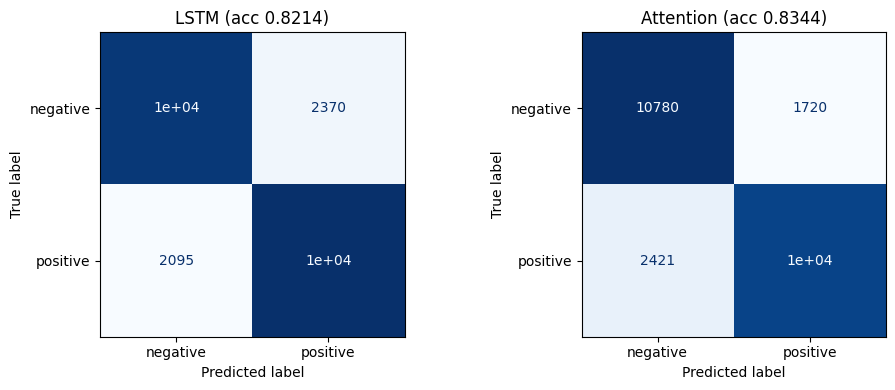

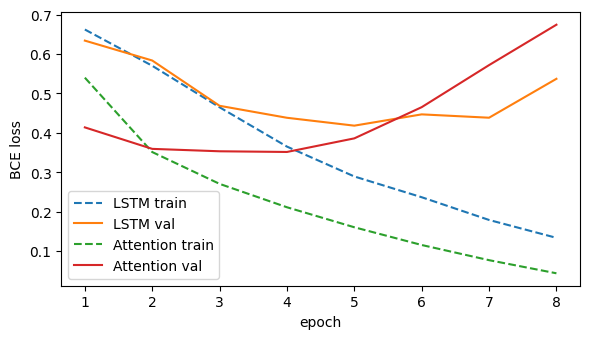

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (kind, r) in zip(axes, RUNS.items()):
    cm = confusion_matrix(y_test, r["y_pred"])
    ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{kind} (acc {r['row']['accuracy']:.4f})")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
for kind, r in RUNS.items():
    h = r["history"]; ax.plot(h["epoch"], h["train_loss"], "--", label=f"{kind} train"); ax.plot(h["epoch"], h["val_loss"], label=f"{kind} val")
ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss"); ax.legend(); plt.tight_layout(); plt.savefig("learning_curves.png", dpi=150); plt.show()

**Representation của hai model khác nhau ở đâu? (Bảng so sánh, vì sao Attention thắng/thua):**

**Biểu diễn:** LSTM nén cả câu vào hidden state cuối (đọc tuần tự, thông tin đầu câu phải đi qua nhiều bước); Attention tạo context `c = Σ αᵢhᵢ`, tổ hợp có trọng số của mọi token nên mọi vị trí đóng góp trực tiếp, không phụ thuộc khoảng cách. **Kết quả:** Attention test acc 0.8344 / F1 0.8296, LSTM 0.8214 / 0.8233; Attention train 21.9s so với 74.3s và val loss tốt nhất thấp hơn (0.351 so với 0.418). Tuy vậy: (1) chỉ 1 seed, chênh ~1.3 điểm nên chưa kết luận Attention thắng; (2) pooling attention gần uniform nên model gần giống mean-pooling, nghĩa là lợi thế có thể đến từ việc không nén qua chuỗi tuần tự chứ không phải từ việc "chọn token"; (3) Attention overfit rất nhanh (val loss tăng từ epoch 4: 0.351 → 0.674 ở epoch 8, trong khi train loss giảm xuống 0.043), nên early stopping là quan trọng. Attention nhanh hơn rõ ràng, nhưng dùng peak GPU memory cao hơn (255 MB so với 178 MB).

## 6. Experiment 3 — Attention visualization (self-attention của model đã train)

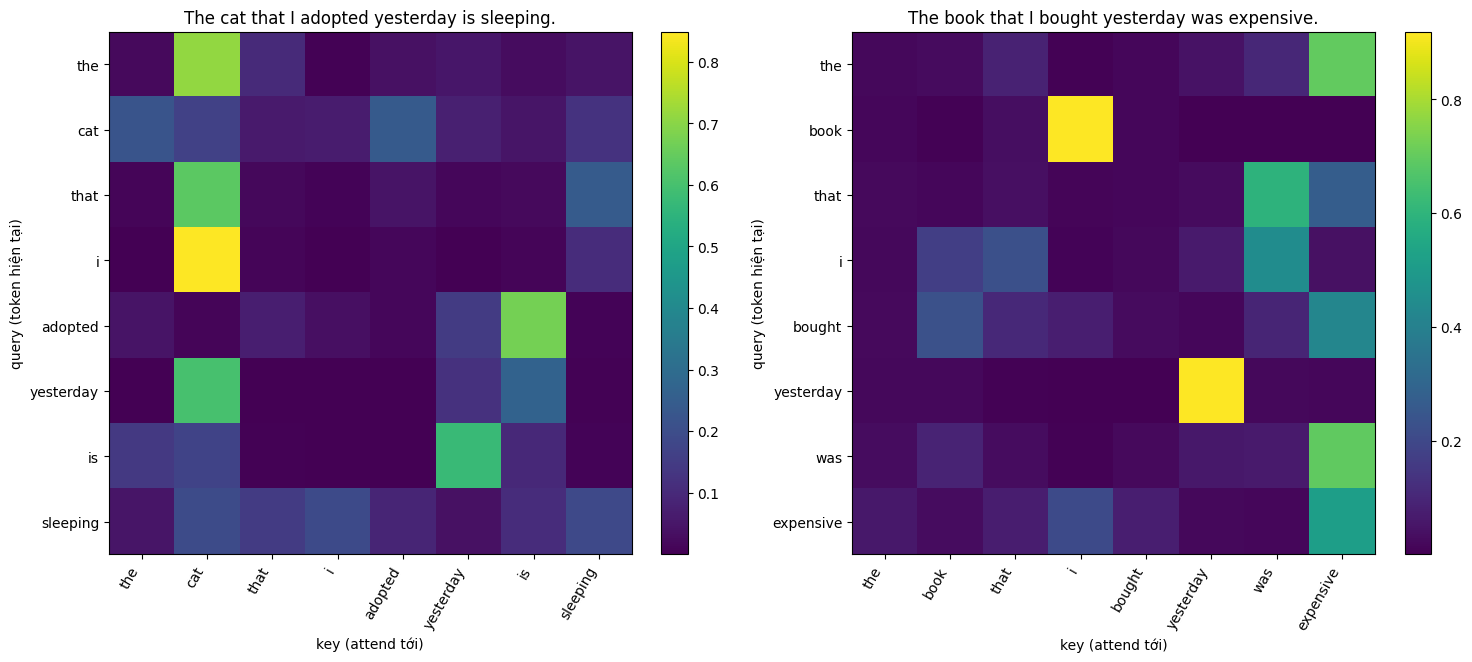

,token,top-3 attend tới,attend tới chính nó
0,cat,"adopted (0.24), the (0.22), cat (0.16)",0.164
1,adopted,"is (0.67), yesterday (0.15), that (0.07)",0.014
2,sleeping,"cat (0.20), i (0.19), sleeping (0.19)",0.188


In [11]:
model = RUNS["Attention"]["model"]; model.eval()

def encode_text(text):
    toks = pp.tokenize(text)[:MAX_LEN]
    ids = torch.tensor([vocab.encode(toks) or [pp.UNK]], device=am.DEVICE)
    return toks, ids, torch.tensor([ids.size(1)])

@torch.no_grad()
def attend(text):
    toks, ids, ln = encode_text(text)
    logit, A, alpha = model(ids, ln, return_attention=True)
    return toks, torch.sigmoid(logit).item(), A[0].cpu().numpy(), alpha[0].cpu().numpy()

def heatmap(ax, A, toks, title):
    im = ax.imshow(A, cmap="viridis"); ax.set_xticks(range(len(toks)), toks, rotation=60, ha="right"); ax.set_yticks(range(len(toks)), toks)
    ax.set_xlabel("key (attend tới)"); ax.set_ylabel("query (token hiện tại)"); ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.046)

sents = ["The cat that I adopted yesterday is sleeping.", "The book that I bought yesterday was expensive."]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5)); out = {}
for ax, s in zip(axes, sents):
    toks, p, A, alpha = attend(s); out[s] = (toks, A)
    heatmap(ax, A, toks, s)
plt.tight_layout(); plt.savefig("attention_heatmap.png", dpi=150); plt.show()

toks, A = out[sents[0]]
rows = []
for t in ("cat", "adopted", "sleeping"):
    i = toks.index(t); top = np.argsort(-A[i])[:3]
    rows.append({"token": t, "top-3 attend tới": ", ".join(f"{toks[j]} ({A[i, j]:.2f})" for j in top), "attend tới chính nó": round(float(A[i, i]), 3)})
pd.DataFrame(rows)

**Mô tả attention pattern (nhớ phân biệt attention pattern với linguistic explanation; lưu ý model không có positional encoding):**

Ở câu "The cat that I adopted yesterday is sleeping.", pattern không có cấu trúc rõ ràng: "cat" attend tới "adopted" (0.24), "the" (0.22) và chính nó (0.16); "adopted" dồn 0.67 vào "is" và gần như không attend tới chính nó (0.014); "sleeping" chia khá đều giữa "cat" (0.20), "i" (0.19) và chính nó (0.19). Thấy "cat" kết nối với "adopted" và "sleeping" chỉ là một pattern, chưa thể khẳng định model hiểu quan hệ chủ-vị hay mệnh đề quan hệ, vì model không có positional encoding (không biết thứ tự/khoảng cách, nên nhiều pattern có thể chỉ phản ánh từ khóa/embedding giống nhau) và model chỉ được huấn luyện cho phân loại cảm xúc, không phải cú pháp. Đây là attention pattern chứ không phải linguistic explanation.

## 7. Experiment 5 — chi phí O(T²)

,T,Attention matrix,Số phần tử,Bộ nhớ float32 (MB),Thời gian NumPy (s)
0,10,10×10,100,0.0004,0.0001
1,100,100×100,10000,0.0381,0.0006
2,500,500×500,250000,0.9537,0.0135
3,1000,1000×1000,1000000,3.8147,0.0378
4,2000,2000×2000,4000000,15.2588,0.1386
5,4000,4000×4000,16000000,61.0352,0.5939
6,10000,10000×10000,100000000,381.4697,NaN


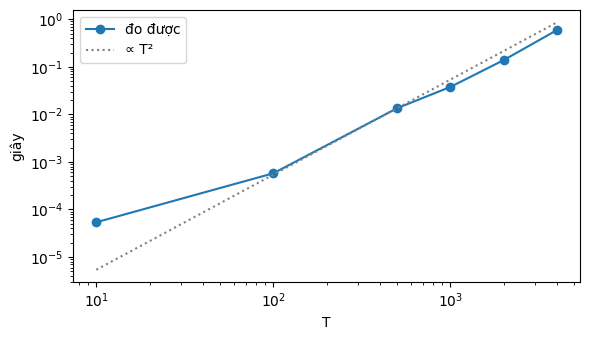

In [12]:
def attention_cost(T, d=64, reps=3):
    rng = np.random.default_rng(0); Q = rng.normal(size=(T, d)).astype(np.float32); Kk = Q.copy(); Vv = Q.copy()
    best = 1e9
    for _ in range(reps):
        t0 = time.perf_counter(); an.scaled_dot_product_attention(Q, Kk, Vv); best = min(best, time.perf_counter() - t0)
    return best

rows = []
for T in (10, 100, 500, 1000, 2000, 4000):
    rows.append({"T": T, "Attention matrix": f"{T}×{T}", "Số phần tử": T * T, "Bộ nhớ float32 (MB)": T * T * 4 / 2**20,
                 "Thời gian NumPy (s)": attention_cost(T)})
for T in (10_000,):
    rows.append({"T": T, "Attention matrix": f"{T}×{T}", "Số phần tử": T * T, "Bộ nhớ float32 (MB)": T * T * 4 / 2**20, "Thời gian NumPy (s)": np.nan})
cost = pd.DataFrame(rows); display(cost.round(4))
fig, ax = plt.subplots(figsize=(6, 3.5)); m = cost.dropna()
ax.loglog(m["T"], m["Thời gian NumPy (s)"], "o-", label="đo được"); ax.loglog(m["T"], m["Thời gian NumPy (s)"].iloc[2] * (m["T"] / 500) ** 2, ":", c="gray", label="∝ T²")
ax.set_xlabel("T"); ax.set_ylabel("giây"); ax.legend(); plt.tight_layout(); plt.show()

**Vì sao self-attention tốn kém khi sequence rất dài? Sequence dài gấp đôi thì sao?**

Ma trận attention có T×T phần tử (mỗi token tính score với mọi token) nên thời gian và bộ nhớ đều O(T²) (còn nhân với số head và số layer). Số đo: T=1000 có 1,000,000 phần tử (3.8 MB float32), T=4000 có 16,000,000 (61 MB), T=10,000 là 100,000,000 phần tử (khoảng 381 MB cho một ma trận, một head). Thời gian NumPy đo được cũng tăng xấp xỉ theo T²: T=1000 → 2000 từ 0.0378s lên 0.1386s (~3.7×), 2000 → 4000 lên 0.5939s (~4.3×). Sequence dài gấp đôi thì chi phí tăng gấp ~4 lần `(2T)² = 4T²`; dài gấp 10 thì ~100 lần. Vì vậy với chuỗi rất dài cần sparse/local attention, linear attention hoặc FlashAttention.

## 8. Application — context-aware sentiment

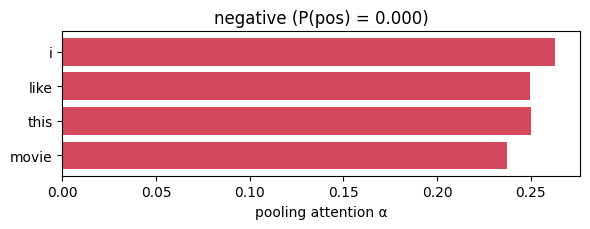

'I like this movie.' -> negative (P(pos)=0.000)
   attention: {'i': np.float32(0.263), 'like': np.float32(0.249), 'this': np.float32(0.25), 'movie': np.float32(0.237)} 



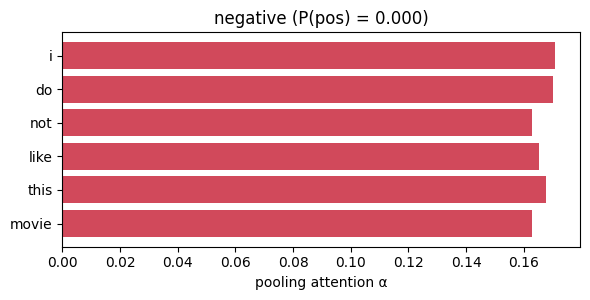

'I do not like this movie.' -> negative (P(pos)=0.000)
   attention: {'i': np.float32(0.171), 'do': np.float32(0.17), 'not': np.float32(0.163), 'like': np.float32(0.165), 'this': np.float32(0.168), 'movie': np.float32(0.163)} 



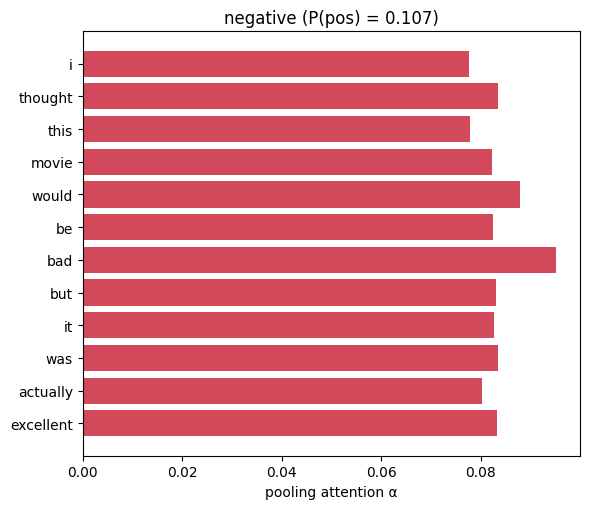

'I thought this movie would be bad, but it was actually excellent.' -> negative (P(pos)=0.107)
   attention: {'i': np.float32(0.078), 'thought': np.float32(0.083), 'this': np.float32(0.078), 'movie': np.float32(0.082), 'would': np.float32(0.088), 'be': np.float32(0.083), 'bad': np.float32(0.095), 'but': np.float32(0.083), 'it': np.float32(0.083), 'was': np.float32(0.084), 'actually': np.float32(0.08), 'excellent': np.float32(0.083)} 



In [13]:
def predict_sentiment(text, plot=True):
    toks, p, A, alpha = attend(text)
    label = "positive" if p >= 0.5 else "negative"
    if plot:
        fig, ax = plt.subplots(figsize=(6, 0.35 * len(toks) + 1))
        ax.barh(toks[::-1], alpha[::-1], color="#d1495b"); ax.set_xlabel("pooling attention α")
        ax.set_title(f"{label} (P(pos) = {p:.3f})"); plt.tight_layout(); plt.show()
    return label, p, dict(zip(toks, alpha.round(3)))

for s in ["I like this movie.", "I do not like this movie.", "I thought this movie would be bad, but it was actually excellent."]:
    label, p, att = predict_sentiment(s); print(f"{s!r} -> {label} (P(pos)={p:.3f})\n   attention:", att, "\n")

**Phân tích ít nhất 1 prediction đúng và 1 sai (hypothesis, không kết luận 'attention nhìn sai từ'):**

**Prediction đúng (hypothesis):** trong error analysis, mẫu #16074 (positive, P(pos) = 0.906) được dự đoán đúng; ở đó có nhiều từ khen ("incredible", "powerful", "great") nên có thể biểu diễn trung bình nghiêng về positive. Chưa chứng minh được vì top-5 attention là các từ không liên quan ("should", "disability"), mỗi từ chỉ 0.01.

**Prediction sai:** "I like this movie." bị dự đoán negative (P(pos) = 0.000) và "I do not like this movie." cũng negative; câu thứ 3 ("... bad, but it was actually excellent") ra negative với P = 0.107 dù ý chung là positive. Attention gần uniform (0.24–0.26 cho câu 4 token, ~0.08 cho câu 12 token; "bad" 0.095 chỉ nhỉnh hơn "excellent" 0.083), nên không thể nói model "nhìn sai từ". Hypothesis: (1) câu rất ngắn khác xa review ~200 token lúc train (domain shift về độ dài); (2) không có positional encoding nên model không phân biệt "not like" với "like" hay cấu trúc "bad, but excellent"; (3) "bad" có thể mang tín hiệu tiêu cực mạnh hơn "excellent" trong dữ liệu train. Cả ba chưa được kiểm chứng; cần thử câu có độ dài gần review hoặc hoán đổi vị trí các từ.

## 9. Dữ liệu cho error analysis (3 đúng + 3 sai)

In [14]:
r = RUNS["Attention"]; proba, pred = r["proba"], r["y_pred"]
rng = np.random.default_rng(42)
correct = rng.choice(np.where(pred == y_test)[0], 3, replace=False)
wrong = rng.choice(np.where(pred != y_test)[0], 3, replace=False)

def top_tokens(i, k=5):
    toks = test_df["tokens"].iloc[i][:MAX_LEN]
    ids = torch.tensor([vocab.encode(toks)], device=am.DEVICE)
    with torch.no_grad():
        _, _, alpha = model(ids, torch.tensor([len(toks)]), return_attention=True)
    a = alpha[0].cpu().numpy(); idx = np.argsort(-a)[:k]
    return ", ".join(f"{toks[j]}({a[j]:.2f})" for j in idx)

rows = []
for tag, idxs in (("đúng", correct), ("sai", wrong)):
    for i in idxs:
        rows.append({"idx": int(i), "nhóm": tag, "true": pp.LABEL_NAMES[y_test[i]], "pred": pp.LABEL_NAMES[pred[i]], "P(pos)": round(float(proba[i]), 3),
                     "n_tokens": int(test_df['n_tokens'].iloc[i]), "top-5 attended": top_tokens(i), "text (300 ký tự đầu)": test_df["text"].iloc[i][:300].replace("<br />", " ")})
errs = pd.DataFrame(rows); errs.to_csv("error_samples.csv", index=False); errs.drop(columns="text (300 ký tự đầu)")

,idx,nhóm,true,pred,P(pos),n_tokens,top-5 attended
0,16074,đúng,positive,positive,0.906,170,"should(0.01), should(0.01), disability(0.01), getting(0.01), only(0.01)"
1,2153,đúng,negative,negative,0.002,160,"mouth(0.01), vanessa(0.01), gay(0.01), gay(0.01), boring(0.01)"
2,19171,đúng,positive,positive,0.995,106,"didn't(0.01), dread(0.01), dread(0.01), permission(0.01), permission(0.01)"
3,2571,sai,negative,positive,0.783,198,"bad(0.01), should(0.01), donald(0.01), donald(0.01), cult(0.01)"
4,18371,sai,positive,negative,0.381,190,"blame(0.01), detention(0.01), couldn't(0.01), violated(0.01), however(0.01)"
5,21895,sai,positive,negative,0.219,181,"anti(0.01), terrible(0.01), nazi(0.01), any(0.01), nemesis(0.01)"


In [15]:
for _, row in errs.iterrows():
    print(f"[{row['idx']}] {row['nhóm']} | true={row['true']} pred={row['pred']} P={row['P(pos)']} | n_tokens={row['n_tokens']}\n   {row['text (300 ký tự đầu)']}\n")

[16074] đúng | true=positive pred=positive P=0.906 | n_tokens=170
   This is an incredible piece of drama and powerful which hits you. I found the film was great and getting to grips with the two main characters disability, this was represented in a great performance by both two Michael and Rory. Whether the story is based around a true story I feel the story was try

[2153] đúng | true=negative pred=negative P=0.002 | n_tokens=160
   The plot for a movie such of this is a giveaway. How can you go wrong with a gay plot line and all the colors and music of India - a story like this writes itself. I'll watch most anything, but this was unwatchable. The sad thing is, the white folks are the most colorful in the film. Vanessa was a r

[19171] đúng | true=positive pred=positive P=0.995 | n_tokens=106
   of Adam's apple and With Your Permission. I didn't know until looking it up just now. Also the errrrrrmmmmm 'Wilbur Wants to Kill himself' I prefer this very focused deadpan ...drama over Ad